# 05 — Final model evaluation


In [1]:
import pandas as pd
import numpy as np
import joblib
import json
from pathlib import Path
BASE = Path("..")
# Dataset path
# DATA_PATH = "../data/processed/cleaned_reviews.csv"
# DATA_PATH = BASE/ "data" / "raw" / "patient_medicine_reviews_enhanced.csv"
# DATA_PATH = BASE / "data" / "raw" / "medireview_comprehensive_60000.csv"
DATA_PATH = BASE / "data" / "raw" / "pharmacy_review.csv"


# Load dataset
df = pd.read_csv(DATA_PATH)

df.head()

,id,gender,age,medicine,condition,review,label
0,0,Male,76.0,Glimepiride,Type 2 Diabetes,I am still waiting to see if the intended bene...,neutral
1,1,Female,44.0,Sertraline,Depression,My calendar has nausea beginning on the twenty...,side effect
2,2,Female,58.0,Diclofenac,Pain,I am keeping track of how Diclofenac is going ...,no side effect
3,3,Female,31.0,Carbimazole,Hyperthyroidism,This is an update from my Carbimazole treatmen...,side effect
4,4,Male,41.0,Escitalopram,Depression,Started a course of Escitalopram for depressio...,side effect


Test Accuracy: 0.8702083333333334

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1600
           1       0.80      0.82      0.81      1600
           2       0.81      0.80      0.80      1600

    accuracy                           0.87      4800
   macro avg       0.87      0.87      0.87      4800
weighted avg       0.87      0.87      0.87      4800



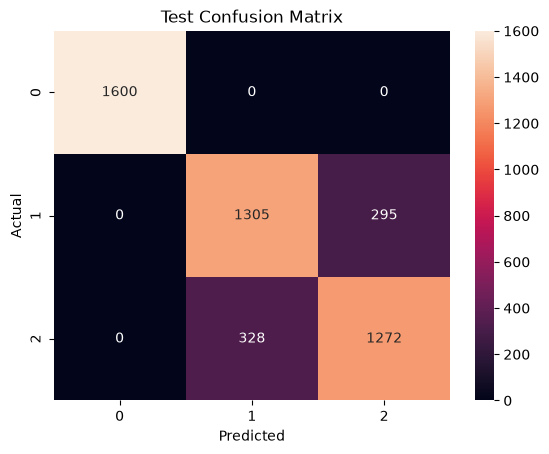


Predictions saved successfully.


In [2]:
import pandas as pd
import joblib
import json
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.sparse import load_npz
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


# 1. Load best model
model = joblib.load("../models/best_model.joblib")

# 2. Load TF-IDF
tfidf = joblib.load("../artifacts/tfidf.joblib")

# 3. Load label mapping
with open("../artifacts/label_mapping.json", "r") as file:
    label_dict = json.load(file)

# Convert {name: id} → {id: name}
id_to_label = {value: key for key, value in label_dict.items()}


# 4. Load test data
test = pd.read_csv("../data/processed/test.csv")

y_test = test["label"]


# 5. Load test TF-IDF features
X_test = load_npz("../artifacts/X_test_tfidf.npz")


# 6. Make predictions
y_pred = model.predict(X_test)


# 7. Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Test Accuracy:", accuracy)


# 8. Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


# 9. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Test Confusion Matrix")
plt.show()


# 10. Add predictions to test data
test["predicted_label"] = [
    id_to_label[int(i)] for i in y_pred
]

test["actual_label"] = [
    id_to_label[int(i)] for i in y_test
]


# 11. Save predictions
test.to_csv(
    "../reports/test_predictions.csv",
    index=False
)

print("\nPredictions saved successfully.")